# MAML Model

# Ablation Study

Using device: cuda
Upload your 3 CSV files:
1. preprocessed_augmented_dataset_scaled.csv
2. validation_set_scaled.csv
3. test_set_scaled.csv


Saving preprocessed_augmented_dataset_scaled.csv to preprocessed_augmented_dataset_scaled.csv
Saving test_set_scaled.csv to test_set_scaled.csv
Saving validation_set_scaled.csv to validation_set_scaled.csv
Training file:   preprocessed_augmented_dataset_scaled.csv
Validation file: validation_set_scaled.csv
Test file:       test_set_scaled.csv
Number of features: 19 | Number of classes: 10

Running variant: 0_baseline

PRETRAINING


Pretrain Epoch 1/3:   0%|          | 0/782 [00:00<?, ?it/s]

Pretrain Epoch 2/3:   0%|          | 0/782 [00:00<?, ?it/s]

Pretrain Epoch 3/3:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 3/3, Loss: 0.405881

FINE-TUNING


... (108 outputs left out)

Fine-tune Epoch 2/2:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 2/2 | Train Acc: 0.7649 | Val Acc: 0.7890


Evaluating:   0%|          | 0/3 [00:00<?, ?it/s]

  -> Accuracy: 0.7964 | F1: 0.7820 | Params: 1,572,747

ABLATION STUDY RESULTS (sorted by F1 score, weighted)
               variant  accuracy  precision   recall       f1  params
          8_no_dropout  0.939210   0.939350 0.939210 0.939066 1572747
           6_two_heads  0.826748   0.813013 0.826748 0.813055 1572747
            0_baseline  0.826748   0.813951 0.826748 0.812752 1572747
3_no_gradient_clipping  0.826748   0.813951 0.826748 0.812752 1572747
        10_higher_mask  0.826748   0.813284 0.826748 0.809815 1572747
  2_no_label_smoothing  0.823708   0.810505 0.823708 0.809536 1572747
 9_no_weighted_sampler  0.820669   0.807729 0.820669 0.806326 1572747
      1_no_pretraining  0.802432   0.783714 0.802432 0.783014 1572747
         11_no_masking  0.796353   0.777815 0.796353 0.782049 1572747
 4_no_dropout_ensemble  0.793313   0.782813 0.793313 0.776869 1572747
     7_smaller_d_model  0.747720   0.730882 0.747720 0.705147  397259
        5_single_layer  0.711246   0.694162 0.7112

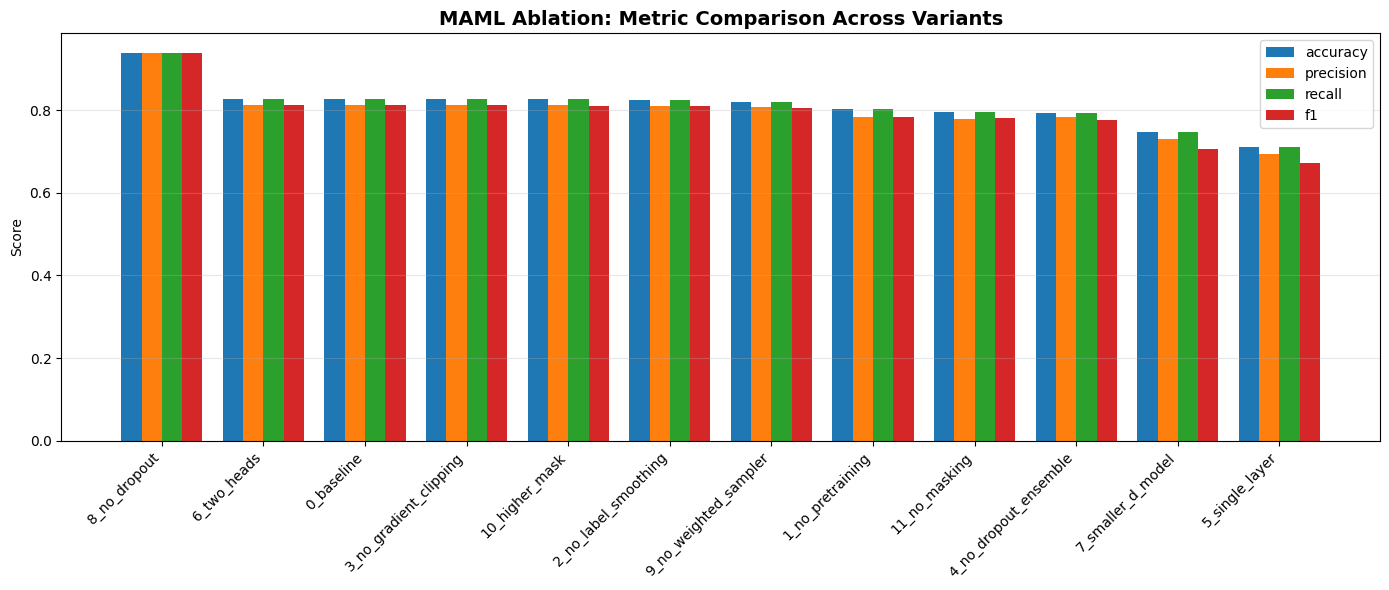

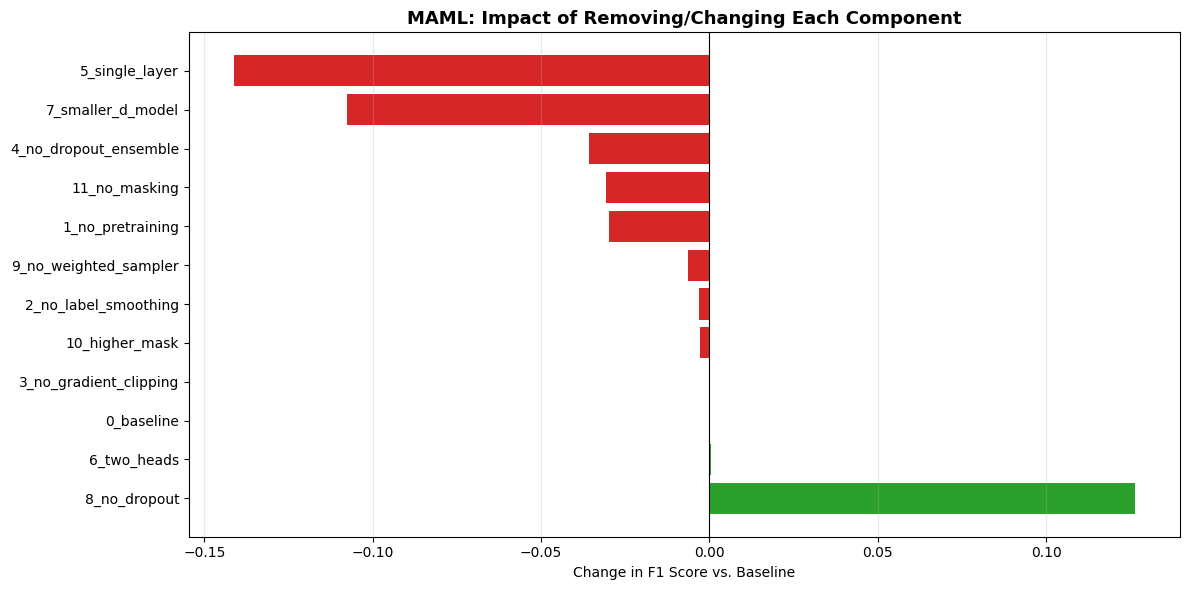

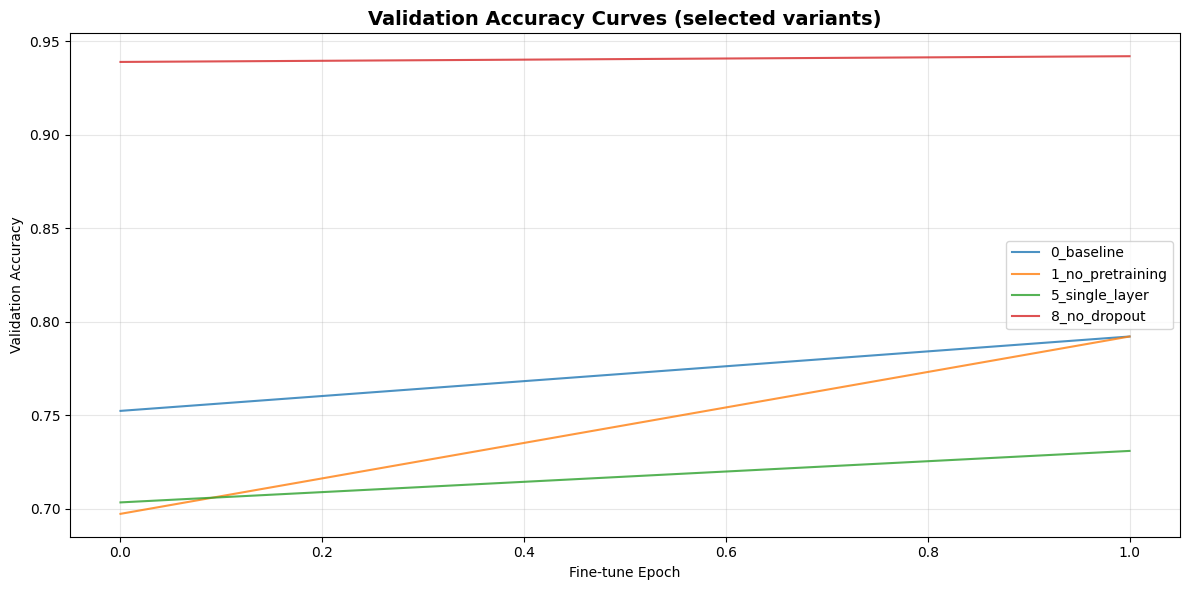


Saved plots: maml_ablation_metric_comparison.png, maml_ablation_delta_from_baseline.png, maml_ablation_val_curves.png

SUMMARY: Component Impact (F1 delta vs baseline)
               variant  f1_delta  params
        5_single_layer -0.141203  583179
     7_smaller_d_model -0.107605  397259
 4_no_dropout_ensemble -0.035883 1572747
         11_no_masking -0.030703 1572747
      1_no_pretraining -0.029738 1572747
 9_no_weighted_sampler -0.006426 1572747
  2_no_label_smoothing -0.003216 1572747
        10_higher_mask -0.002937 1572747
3_no_gradient_clipping  0.000000 1572747
           6_two_heads  0.000303 1572747
          8_no_dropout  0.126314 1572747


In [ ]:
# ============================================================
# ABLATION STUDY: MAML (MODEL-AGNOSTIC META-LEARNING) FOR BEARING FAULT DETECTION
# Variants tested:
#   0. Full model (baseline)
#   1. No masked feature pretraining
#   2. No label smoothing
#   3. No gradient clipping
#   4. No dropout ensemble during inference
#   5. Single Transformer layer instead of 4-layer encoder
#   6. Reduced attention heads (4->2)
#   7. Smaller embedding dimension (128->64)
#   8. No dropout regularization
#   9. No weighted sampler (imbalance handling removed)
#   10. Higher masking ratio (0.2->0.4)
#   11. No masking during pretraining
# ============================================================
# ============================================================

# !pip -q install torch torchvision torchaudio pandas numpy scikit-learn tqdm matplotlib

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm
from google.colab import files
warnings.filterwarnings('ignore')

# ============================================================
# 1. Configuration & Constants
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

SEED = 42
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Default configuration
DEFAULT_CONFIG = {
    "name": "baseline",
    "mask_ratio": 0.20,
    "replace_with_mask": 0.8,
    "replace_with_random": 0.1,
    "replace_with_same": 0.1,
    "batch_size": 128,
    "epochs_pretrain": 70,          # will be reduced for ablation speed
    "epochs_finetune": 20,
    "patience": 5,
    "lr_pretrain": 1e-4,
    "lr_finetune": 5e-5,
    "weight_decay": 5e-4,
    "d_model": 128,
    "n_heads": 4,
    "n_layers": 4,
    "dropout": 0.3,
    "use_label_smoothing": True,
    "label_smoothing": 0.1,
    "use_gradient_clipping": True,
    "gradient_clip_norm": 5.0,
    "use_dropout_ensemble": True,
    "num_passes": 15,
    "use_weighted_sampler": True,
    "use_pretraining": True,
    "finetune_noise_std": 0.01,
}

# ============================================================
# 2. Data Loading
# ============================================================
print("Upload your 3 CSV files:")
print("1. preprocessed_augmented_dataset_scaled.csv")
print("2. validation_set_scaled.csv")
print("3. test_set_scaled.csv")
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def choose_file(kind):
    lower_names = [name.lower() for name in uploaded_names]
    if kind == "train":
        keywords = ["augmented", "train", "training", "preprocessed"]
    elif kind == "val":
        keywords = ["validation", "val"]
    elif kind == "test":
        keywords = ["test"]
    else:
        keywords = []
    candidates = [orig for orig, low in zip(uploaded_names, lower_names) if any(k in low for k in keywords)]
    if len(candidates) == 1:
        return candidates[0]
    print(f"Could not automatically choose the {kind} file. Available: {uploaded_names}")
    idx = int(input(f"Enter the index of the {kind} file: "))
    return uploaded_names[idx]

train_file = choose_file("train")
val_file   = choose_file("val")
test_file  = choose_file("test")
print("Training file:  ", train_file)
print("Validation file:", val_file)
print("Test file:      ", test_file)

# Load and preprocess data (identical to original)
train_df = pd.read_csv(train_file)
val_df   = pd.read_csv(val_file)
test_df  = pd.read_csv(test_file)

TARGET_COL = "fault_encoded"
if TARGET_COL not in train_df.columns:
    raise ValueError(f"Target column '{TARGET_COL}' not found. Columns: {list(train_df.columns)}")

feature_cols = [c for c in train_df.columns if c != TARGET_COL]
for df in [train_df, val_df, test_df]:
    for col in feature_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df[feature_cols] = df[feature_cols].fillna(0)

label_encoder = LabelEncoder()
all_labels = pd.concat([train_df[TARGET_COL], val_df[TARGET_COL], test_df[TARGET_COL]], axis=0)
label_encoder.fit(all_labels)

X_train = train_df[feature_cols].values.astype(np.float32)
y_train = label_encoder.transform(train_df[TARGET_COL])
X_val   = val_df[feature_cols].values.astype(np.float32)
y_val   = label_encoder.transform(val_df[TARGET_COL])
X_test  = test_df[feature_cols].values.astype(np.float32)
y_test  = label_encoder.transform(test_df[TARGET_COL])

n_features = X_train.shape[1]
n_classes = len(label_encoder.classes_)
print("Number of features:", n_features, "| Number of classes:", n_classes)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t   = torch.tensor(X_val_scaled,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test_scaled,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t   = torch.tensor(y_val,   dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

# Class weights for balanced sampling
class_weights_np = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
sample_weights = class_weights_np[y_train]
sample_weights_t = torch.tensor(sample_weights, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t,   y_val_t)
test_dataset  = TensorDataset(X_test_t,  y_test_t)

def make_loaders(cfg):
    batch_size = cfg["batch_size"]
    if cfg["use_weighted_sampler"]:
        sampler = WeightedRandomSampler(sample_weights_t, len(sample_weights_t), replacement=True)
        train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=0)
    else:
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    return train_loader, val_loader, test_loader

# ============================================================
# 3. Random Masking and Pretrain Dataset
# ============================================================
def random_masking(x, cfg):
    mask_ratio = cfg["mask_ratio"]
    batch_size, n_feat = x.shape
    mask = torch.zeros_like(x, dtype=torch.bool)
    num_mask = max(1, int(n_feat * mask_ratio))
    masked_x = x.clone()
    for i in range(batch_size):
        indices = torch.randperm(n_feat)[:num_mask]
        for idx in indices:
            r = torch.rand(1).item()
            if r < cfg["replace_with_mask"]:
                masked_x[i, idx] = 0.0
                mask[i, idx] = True
            elif r < cfg["replace_with_mask"] + cfg["replace_with_random"]:
                random_idx = torch.randint(0, batch_size, (1,)).item()
                masked_x[i, idx] = x[random_idx, idx]
                mask[i, idx] = True
            else:
                mask[i, idx] = False
    return masked_x, mask

class MAMLDataset(torch.utils.data.Dataset):
    def __init__(self, X, cfg, pretrain=True):
        self.X = X
        self.cfg = cfg
        self.pretrain = pretrain
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        x = self.X[idx]
        if self.pretrain:
            x_batch = x.unsqueeze(0)
            masked_x, mask = random_masking(x_batch, self.cfg)
            return masked_x.squeeze(0), mask.squeeze(0), x
        else:
            return x, self.y[idx] if hasattr(self, 'y') else x

# ============================================================
# 4. Model Definition (configurable)
# ============================================================
class OptimizedmamlTransformer(nn.Module):
    def __init__(self, cfg, n_features, n_classes):
        super().__init__()
        self.cfg = cfg
        self.n_features = n_features
        self.d_model = cfg["d_model"]
        self.n_classes = n_classes

        self.feature_embedding = nn.Linear(1, self.d_model)
        self.mask_token = nn.Parameter(torch.randn(1, 1, self.d_model) * 0.02)
        self.cls_token = nn.Parameter(torch.randn(1, 1, self.d_model) * 0.02)
        self.pos_embedding = nn.Parameter(torch.randn(1, n_features + 1, self.d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.d_model,
            nhead=cfg["n_heads"],
            dim_feedforward=self.d_model * 8,
            dropout=cfg["dropout"],
            batch_first=True,
            activation='gelu',
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=cfg["n_layers"])
        self.layer_norm = nn.LayerNorm(self.d_model)
        self.dropout = nn.Dropout(cfg["dropout"])

        self.reconstruction_head = nn.Sequential(
            nn.Linear(self.d_model, self.d_model),
            nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(self.d_model, 1)
        )

        self.classification_head = nn.Sequential(
            nn.Linear(self.d_model, self.d_model * 4),
            nn.BatchNorm1d(self.d_model * 4),
            nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(self.d_model * 4, self.d_model * 2),
            nn.BatchNorm1d(self.d_model * 2),
            nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(self.d_model * 2, self.d_model),
            nn.BatchNorm1d(self.d_model),
            nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(self.d_model, n_classes)
        )

        self.pretraining_mode = True

    def forward(self, x, mask=None):
        batch_size, n_feat = x.shape
        x = x.unsqueeze(-1)
        x = self.feature_embedding(x)
        if mask is not None:
            mask_expanded = mask.unsqueeze(-1).expand(-1, -1, self.d_model)
            mask_token_expanded = self.mask_token.expand(batch_size, n_feat, self.d_model)
            x = torch.where(mask_expanded, mask_token_expanded, x)

        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        x = x + self.pos_embedding[:, :x.size(1), :]
        x = self.dropout(x)
        x = self.transformer(x)
        x = self.layer_norm(x)

        if self.pretraining_mode:
            reconstructions = self.reconstruction_head(x[:, 1:, :])
            return reconstructions.squeeze(-1)
        else:
            cls_representation = x[:, 0]
            logits = self.classification_head(cls_representation)
            return logits

    def switch_to_finetune(self):
        self.pretraining_mode = False

# ============================================================
# 5. Training Functions (config-aware)
# ============================================================
def pretrain_maml(model, cfg, train_loader, epochs):
    print("\n" + "="*70)
    print("PRETRAINING")
    print("="*70)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg["lr_pretrain"],
        weight_decay=cfg["weight_decay"],
        betas=(0.9, 0.98)
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    model.train()
    model.pretraining_mode = True
    losses = []

    for epoch in range(1, epochs + 1):
        total_loss = 0.0
        num_batches = 0
        progress_bar = tqdm(train_loader, desc=f"Pretrain Epoch {epoch}/{epochs}", leave=False)
        for masked_x, mask, original_x in progress_bar:
            masked_x, mask, original_x = masked_x.to(DEVICE), mask.to(DEVICE), original_x.to(DEVICE)
            optimizer.zero_grad()
            reconstructions = model(masked_x, mask)
            mask_float = mask.float()
            recon_loss = F.mse_loss(reconstructions, original_x, reduction='none')
            recon_loss = (recon_loss * mask_float).sum() / (mask_float.sum() + 1e-8)
            recon_loss.backward()
            if cfg["use_gradient_clipping"]:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg["gradient_clip_norm"])
            optimizer.step()
            total_loss += recon_loss.item()
            num_batches += 1
            progress_bar.set_postfix({'loss': f"{recon_loss.item():.6f}"})

        avg_loss = total_loss / num_batches
        losses.append(avg_loss)
        scheduler.step()
        if epoch % 10 == 0 or epoch == epochs:
            print(f"Epoch {epoch}/{epochs}, Loss: {avg_loss:.6f}")
    return losses

def finetune_maml(model, cfg, train_loader, val_loader, epochs):
    print("\n" + "="*70)
    print("FINE-TUNING")
    print("="*70)

    model.switch_to_finetune()

    # Compute class weights for fine-tuning loss
    y_train_all = []
    for _, labels in train_loader:
        y_train_all.extend(labels.numpy())
    class_weights = compute_class_weight('balanced', classes=np.unique(y_train_all), y=y_train_all)
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

    # Cross-entropy with optional label smoothing
    if cfg["use_label_smoothing"]:
        criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=cfg["label_smoothing"])
    else:
        criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg["lr_finetune"],
        weight_decay=cfg["weight_decay"],
        betas=(0.9, 0.98)
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val_acc = 0.0
    best_state = None
    patience_counter = 0
    train_accs, val_accs, train_losses, val_losses = [], [], [], []

    for epoch in range(1, epochs + 1):
        model.train()
        train_preds, train_labels = [], []
        train_loss = 0.0

        for xb, yb in tqdm(train_loader, desc=f"Fine-tune Epoch {epoch}/{epochs}", leave=False):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            # Optional input noise
            noise = torch.randn_like(xb) * cfg["finetune_noise_std"]
            xb = xb + noise
            optimizer.zero_grad()
            logits = model(xb, mask=None)
            loss = criterion(logits, yb)
            loss.backward()
            if cfg["use_gradient_clipping"]:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg["gradient_clip_norm"])
            optimizer.step()
            train_loss += loss.item()
            train_preds.extend(logits.argmax(dim=1).cpu().numpy())
            train_labels.extend(yb.cpu().numpy())

        train_acc = accuracy_score(train_labels, train_preds)
        train_accs.append(train_acc)
        train_losses.append(train_loss / len(train_loader))

        model.eval()
        val_preds, val_labels = [], []
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb, mask=None)
                loss = criterion(logits, yb)
                val_loss += loss.item()
                val_preds.extend(logits.argmax(dim=1).cpu().numpy())
                val_labels.extend(yb.cpu().numpy())
        val_acc = accuracy_score(val_labels, val_preds)
        val_accs.append(val_acc)
        val_losses.append(val_loss / len(val_loader))

        scheduler.step()
        print(f"Epoch {epoch}/{epochs} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= cfg["patience"]:
                print(f"Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    return model, best_val_acc, train_accs, val_accs, train_losses, val_losses

def evaluate_model(model, cfg, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in tqdm(loader, desc="Evaluating", leave=False):
            xb = xb.to(DEVICE)
            if cfg["use_dropout_ensemble"]:
                all_probs = []
                for _ in range(cfg["num_passes"]):
                    model.train()
                    logits = model(xb, mask=None)
                    probs = F.softmax(logits, dim=1)
                    all_probs.append(probs.cpu().numpy())
                    model.eval()
                avg_probs = np.mean(all_probs, axis=0)
                preds = np.argmax(avg_probs, axis=1)
            else:
                logits = model(xb, mask=None)
                preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(yb.numpy())
    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'predictions': all_preds,
        'labels': all_labels
    }

# ============================================================
# 6. Run a Single Experiment (pretrain + finetune + eval)
# ============================================================
def run_experiment(cfg):
    set_seed(SEED)  # reset seed for reproducibility
    model = OptimizedmamlTransformer(cfg, n_features, n_classes).to(DEVICE)

    # Create pretrain loader if pretraining is enabled
    if cfg["use_pretraining"]:
        pretrain_dataset = MAMLDataset(X_train_t, cfg, pretrain=True)
        pretrain_loader = DataLoader(pretrain_dataset, batch_size=cfg["batch_size"], shuffle=True, num_workers=0)
    else:
        pretrain_loader = None
        print("Skipping pretraining (use_pretraining=False)")

    # Main loaders
    train_loader, val_loader, test_loader = make_loaders(cfg)

    # Pretraining
    if cfg["use_pretraining"] and pretrain_loader is not None:
        pretrain_losses = pretrain_maml(model, cfg, pretrain_loader, cfg["epochs_pretrain"])
    else:
        pretrain_losses = []

    # Fine-tuning
    model, best_val_acc, train_accs, val_accs, train_losses, val_losses = finetune_maml(
        model, cfg, train_loader, val_loader, cfg["epochs_finetune"]
    )

    # Evaluation with TTA
    test_metrics = evaluate_model(model, cfg, test_loader)

    # Return metrics and histories for possible plotting
    return {
        "variant": cfg["name"],
        "accuracy": test_metrics["accuracy"],
        "precision": test_metrics["precision"],
        "recall": test_metrics["recall"],
        "f1": test_metrics["f1"],
        "params": sum(p.numel() for p in model.parameters()),
        "best_val_acc": best_val_acc,
        "pretrain_losses": pretrain_losses,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
    }

# ============================================================
# 7. Define Ablation Variants
# ============================================================
# We'll reduce epochs for ablation speed (set to lower values)
# The user can increase them if they have time.
ABLATION_EPOCHS_PRETRAIN = 3   # from 70
ABLATION_EPOCHS_FINETUNE = 2   # from 20
ABLATION_PATIENCE = 3           # from 5

def make_cfg(overrides):
    cfg = dict(DEFAULT_CONFIG)
    cfg.update(overrides)
    # Override epochs for ablation speed
    cfg["epochs_pretrain"] = ABLATION_EPOCHS_PRETRAIN
    cfg["epochs_finetune"] = ABLATION_EPOCHS_FINETUNE
    cfg["patience"] = ABLATION_PATIENCE
    return cfg

ablation_variants = [
    # Baseline (original config)
    make_cfg({"name": "0_baseline"}),

    # No pretraining (skip mask reconstruction)
    make_cfg({"name": "1_no_pretraining", "use_pretraining": False}),

    # No label smoothing
    make_cfg({"name": "2_no_label_smoothing", "use_label_smoothing": False}),

    # No gradient clipping
    make_cfg({"name": "3_no_gradient_clipping", "use_gradient_clipping": False}),

    # No dropout ensemble (single forward pass)
    make_cfg({"name": "4_no_dropout_ensemble", "use_dropout_ensemble": False}),

    # Single transformer layer
    make_cfg({"name": "5_single_layer", "n_layers": 1}),

    # Two attention heads (instead of 4)
    make_cfg({"name": "6_two_heads", "n_heads": 2}),

    # Smaller d_model (64 instead of 128)
    make_cfg({"name": "7_smaller_d_model", "d_model": 64}),

    # No dropout (dropout=0.0)
    make_cfg({"name": "8_no_dropout", "dropout": 0.0}),

    # No weighted sampler (use plain shuffling)
    make_cfg({"name": "9_no_weighted_sampler", "use_weighted_sampler": False}),

    # Higher mask ratio (0.4)
    make_cfg({"name": "10_higher_mask", "mask_ratio": 0.4}),

    # Lower mask ratio (0.0, i.e., no masking)
    make_cfg({"name": "11_no_masking", "mask_ratio": 0.0}),
]

# ============================================================
# 8. Run All Experiments
# ============================================================
results = []
all_histories = {}

for cfg in ablation_variants:
    print("\n" + "="*70)
    print(f"Running variant: {cfg['name']}")
    print("="*70)
    result = run_experiment(cfg)
    results.append(result)
    all_histories[cfg['name']] = {
        'pretrain_losses': result['pretrain_losses'],
        'train_losses': result['train_losses'],
        'val_losses': result['val_losses'],
        'train_accs': result['train_accs'],
        'val_accs': result['val_accs'],
    }
    print(f"  -> Accuracy: {result['accuracy']:.4f} | F1: {result['f1']:.4f} | Params: {result['params']:,}")

results_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("ABLATION STUDY RESULTS (sorted by F1 score, weighted)")
print("="*70)
print(results_df[["variant", "accuracy", "precision", "recall", "f1", "params"]].to_string(index=False))

results_df.to_csv("maml_ablation_results.csv", index=False)
print("\nSaved: maml_ablation_results.csv")

# ============================================================
# 9. Visualizations
# ============================================================
baseline_row = results_df[results_df["variant"] == "0_baseline"].iloc[0]

# Bar chart: metric comparison
plt.figure(figsize=(14, 6))
metrics_to_plot = ["accuracy", "precision", "recall", "f1"]
x = np.arange(len(results_df))
width = 0.2
for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, results_df[metric], width, label=metric)
plt.xticks(x + width * 1.5, results_df["variant"], rotation=45, ha='right')
plt.ylabel("Score")
plt.title("MAML Ablation: Metric Comparison Across Variants", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("maml_ablation_metric_comparison.png", dpi=150)
plt.show()

# Delta from baseline (F1)
plt.figure(figsize=(12, 6))
delta_f1 = results_df["f1"] - baseline_row["f1"]
colors = ['#d62728' if v < 0 else '#2ca02c' for v in delta_f1]
plt.barh(results_df["variant"], delta_f1, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Change in F1 Score vs. Baseline")
plt.title("MAML: Impact of Removing/Changing Each Component", fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("maml_ablation_delta_from_baseline.png", dpi=150)
plt.show()

# (Optional) Plot validation accuracy curves for a few key variants
plt.figure(figsize=(12, 6))
for name, hist in all_histories.items():
    if name in ["0_baseline", "1_no_pretraining", "5_single_layer", "8_no_dropout"]:
        plt.plot(hist['val_accs'], label=name, alpha=0.8)
plt.title("Validation Accuracy Curves (selected variants)", fontsize=14, fontweight='bold')
plt.xlabel("Fine-tune Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("maml_ablation_val_curves.png", dpi=150)
plt.show()

print("\nSaved plots: maml_ablation_metric_comparison.png, maml_ablation_delta_from_baseline.png, maml_ablation_val_curves.png")

# ============================================================
# 10. Summary: Component Impact
# ============================================================
print("\n" + "="*70)
print("SUMMARY: Component Impact (F1 delta vs baseline)")
print("="*70)
summary = results_df.copy()
summary["f1_delta"] = summary["f1"] - baseline_row["f1"]
summary = summary[summary["variant"] != "0_baseline"]
summary = summary.sort_values("f1_delta")
print(summary[["variant", "f1_delta", "params"]].to_string(index=False))